In [21]:
#Import pandas
import pandas as pd

#Import the file from Google Colab
from google.colab import files

#Upload the diabetes dataset
uploaded = files.upload()

Saving diabetes.csv to diabetes.csv


In [22]:
#Load the diabetes dataset
df = pd.read_csv("diabetes.csv")

#Display the first 5 rows
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [23]:
#View info
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [24]:
#Display summary
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [25]:
#Check for missing values in each column
df.isnull().sum()

,0
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0


**Part A: Random Sample and Glucose Comparison**

In [26]:
#Take a reproducible random sample of 25 observations
sample_25 = df.sample(n=25, random_state=42)

#Display the sample
sample_25

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
668,6,98,58,33,190,34.0,0.430,43,0
324,2,112,75,32,0,35.7,0.148,21,0
624,2,108,64,0,0,30.8,0.158,21,0
690,8,107,80,0,0,24.6,0.856,34,0
473,7,136,90,0,0,29.9,0.210,50,0
204,6,103,72,32,190,37.7,0.324,55,0
97,1,71,48,18,76,20.4,0.323,22,0
336,0,117,0,0,0,33.8,0.932,44,0
568,4,154,72,29,126,31.3,0.338,37,0
148,5,147,78,0,0,33.7,0.218,65,0


In [27]:
#Calculate the mean and highest Glucose value for the sample
sample_mean_glucose = sample_25['Glucose'].mean()
sample_max_glucose = sample_25['Glucose'].max()

print("Sample Mean Glucose:", round(sample_mean_glucose, 2))
print("Sample Highest Glucose:", sample_max_glucose)

Sample Mean Glucose: 116.64
Sample Highest Glucose: 183


In [28]:
#Calculate the mean and highest Glucose value for the population
population_mean_glucose = df['Glucose'].mean()
population_max_glucose = df['Glucose'].max()

print("Population Mean Glucose:", round(population_mean_glucose, 2))
print("Population Highest Glucose:", population_max_glucose)

Population Mean Glucose: 120.89
Population Highest Glucose: 199


In [29]:
#Create a table to compare sample and population statistics
glucose_comparison = pd.DataFrame({
    'Statistic': ['Mean Glucose', 'Highest Glucose'],
    'Sample': [sample_mean_glucose, sample_max_glucose],
    'Population': [population_mean_glucose, population_max_glucose]
})

#Round values to 2 decimal places
glucose_comparison[['Sample', 'Population']] = (
    glucose_comparison[['Sample', 'Population']].round(2)
)

glucose_comparison

,Statistic,Sample,Population
0,Mean Glucose,116.64,120.89
1,Highest Glucose,183.00,199.00


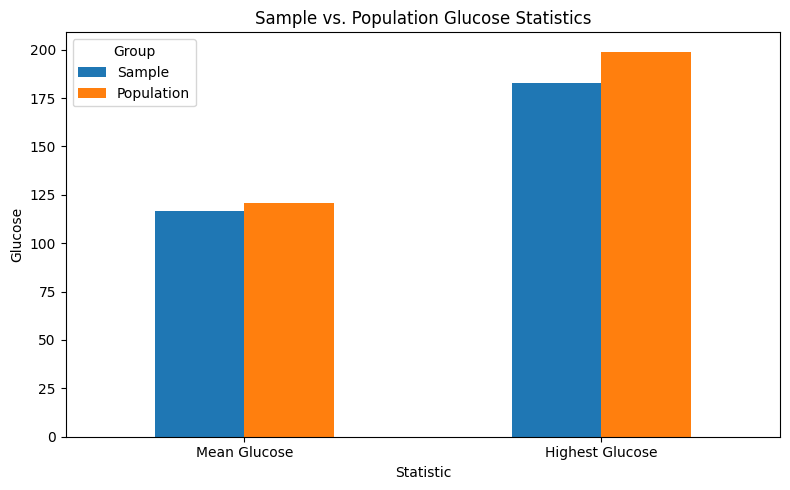

In [30]:
#Import matplotlib for visualization
import matplotlib.pyplot as plt

#Create a bar chart comparing the sample and population
glucose_comparison.set_index('Statistic')[['Sample', 'Population']].plot(
    kind='bar',
    figsize=(8, 5)
)

plt.title('Sample vs. Population Glucose Statistics')
plt.ylabel('Glucose')
plt.xlabel('Statistic')
plt.xticks(rotation=0)
plt.legend(title='Group')
plt.tight_layout()
plt.show()

**Part A (explanation): Random Sample and Glucose Comparison**

A random sample of 25 observations was selected from the population of 768 patients using a random seed of 42 to ensure reproducibility. The sample had a mean Glucose value of 116.64, compared with the population mean of 120.89. This means the sample mean was 4.25 points lower than the population mean.

The highest Glucose value in the sample was 183, while the highest value in the population was 199. This means the sample maximum was 16 points lower than the population maximum.

The bar chart illustrates the differences between the sample and population statistics. Although the sample mean was relatively close to the population mean, the random sample of only 25 observations did not include the highest Glucose value found in the full population. This shows how statistics calculated from a relatively small random sample can differ from the corresponding population parameters.

**Part B: 98th Percentile BMI Comparison**

In [31]:
#Calculate the 98th percentile of BMI for the sample
sample_bmi_98 = sample_25['BMI'].quantile(0.98)

#Calculate the 98th percentile of BMI for the population
population_bmi_98 = df['BMI'].quantile(0.98)

print("Sample 98th Percentile BMI:", round(sample_bmi_98, 2))
print("Population 98th Percentile BMI:", round(population_bmi_98, 2))

Sample 98th Percentile BMI: 40.25
Population 98th Percentile BMI: 47.53


In [32]:
#Create a table comparing the 98th percentile of BMI
bmi_comparison = pd.DataFrame({
    'Group': ['Sample', 'Population'],
    '98th Percentile BMI': [sample_bmi_98, population_bmi_98]
})

#Round values to 2 decimal places
bmi_comparison['98th Percentile BMI'] = (
    bmi_comparison['98th Percentile BMI'].round(2)
)

bmi_comparison

,Group,98th Percentile BMI
0,Sample,40.25
1,Population,47.53


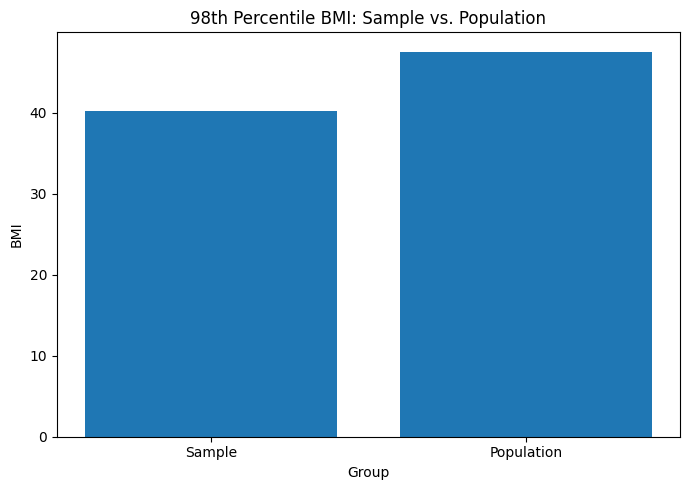

In [33]:
#Create a bar chart comparing the 98th percentile of BMI
plt.figure(figsize=(7, 5))

plt.bar(
    bmi_comparison['Group'],
    bmi_comparison['98th Percentile BMI']
)

plt.title('98th Percentile BMI: Sample vs. Population')
plt.ylabel('BMI')
plt.xlabel('Group')
plt.tight_layout()
plt.show()

In [34]:
#Calculate the difference between the sample and population
bmi_98_difference = sample_bmi_98 - population_bmi_98

print(
    "Difference in 98th Percentile BMI:",
    round(bmi_98_difference, 2)
)

Difference in 98th Percentile BMI: -7.28


**Part B (explanation): 98th Percentile BMI Comparison**

The 98th percentile of BMI was calculated for both the random sample of 25 patients and the full population of 768 patients. The 98th percentile BMI for the sample was 40.25, while the 98th percentile BMI for the population was 47.53. This means the sample value was 7.28 points lower than the population value.

The bar chart illustrates the difference between the sample and population 98th percentile BMI values. The lower percentile value in the sample indicates that BMI values near the upper end of the sample distribution were lower than those in the full population distribution. Because the sample contains only a small portion of the population, differences between the sample statistic and population parameter are expected.

**Part C: Bootstrap Analysis of Blood Pressure**

In [35]:
#Import NumPy for numerical operations
import numpy as np

#Set a seed to ensure reproducibility
np.random.seed(42)

#Number and size of bootstrap samples
number_of_samples = 500
sample_size = 150

#Use the 95th percentile b/c the assignment does not specify a percentile level
percentile_level = 0.95

#Create empty lists to store the bootstrap stats
bootstrap_means = []
bootstrap_standard_deviations = []
bootstrap_percentiles = []

#Create 500 bootstrap samples of 150 observations each
for i in range(number_of_samples):

    bootstrap_sample = df['BloodPressure'].sample(
        n=sample_size,
        replace=True
    )

    #Calculate statistics for the current bootstrap sample
    bootstrap_means.append(bootstrap_sample.mean())
    bootstrap_standard_deviations.append(bootstrap_sample.std(ddof=0))
    bootstrap_percentiles.append(
        bootstrap_sample.quantile(percentile_level)
    )

In [36]:
#Calculate the average statistics across the 500 bootstrap samples
average_bootstrap_mean = np.mean(bootstrap_means)

average_bootstrap_std = np.mean(
    bootstrap_standard_deviations
)

average_bootstrap_percentile = np.mean(
    bootstrap_percentiles
)

print(
    "Average Bootstrap Mean:",
    round(average_bootstrap_mean, 2)
)

print(
    "Average Bootstrap Standard Deviation:",
    round(average_bootstrap_std, 2)
)

print(
    "Average Bootstrap 95th Percentile:",
    round(average_bootstrap_percentile, 2)
)

Average Bootstrap Mean: 69.18
Average Bootstrap Standard Deviation: 19.01
Average Bootstrap 95th Percentile: 91.13


In [37]:
#Calculate the BloodPressure statistics for the population
population_bp_mean = df['BloodPressure'].mean()

population_bp_std = df['BloodPressure'].std(ddof=0)

population_bp_percentile = df['BloodPressure'].quantile(
    percentile_level
)

print(
    "Population Mean:",
    round(population_bp_mean, 2)
)

print(
    "Population Standard Deviation:",
    round(population_bp_std, 2)
)

print(
    "Population 95th Percentile:",
    round(population_bp_percentile, 2)
)

Population Mean: 69.11
Population Standard Deviation: 19.34
Population 95th Percentile: 90.0


In [38]:
#Create a table comparing bootstrap and population statistics
blood_pressure_comparison = pd.DataFrame({
    'Statistic': [
        'Mean',
        'Standard Deviation',
        '95th Percentile'
    ],

    'Average Bootstrap': [
        average_bootstrap_mean,
        average_bootstrap_std,
        average_bootstrap_percentile
    ],

    'Population': [
        population_bp_mean,
        population_bp_std,
        population_bp_percentile
    ]
})

#Calculate the differences
blood_pressure_comparison['Difference'] = (
    blood_pressure_comparison['Average Bootstrap']
    - blood_pressure_comparison['Population']
)

#Round the results to 2 decimal places
blood_pressure_comparison = (
    blood_pressure_comparison.round(2)
)

blood_pressure_comparison

,Statistic,Average Bootstrap,Population,Difference
0,Mean,69.18,69.11,0.07
1,Standard Deviation,19.01,19.34,-0.33
2,95th Percentile,91.13,90.00,1.13


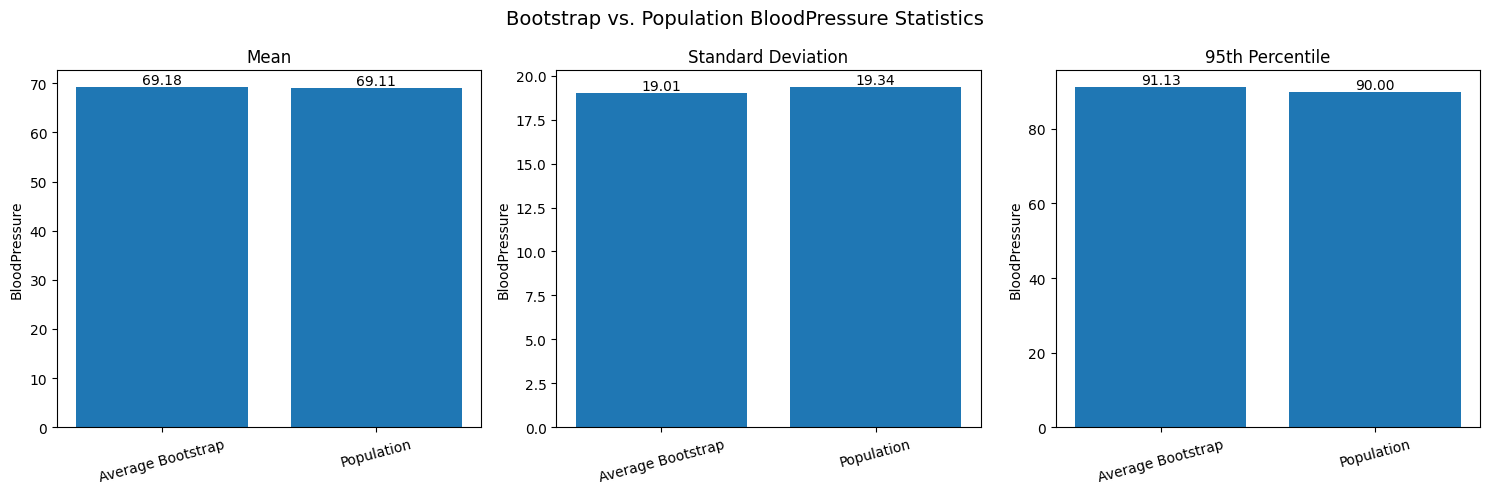

In [39]:
#Create three charts comparing bootstrap and population statistics
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

statistics = [
    'Mean',
    'Standard Deviation',
    '95th Percentile'
]

bootstrap_values = [
    average_bootstrap_mean,
    average_bootstrap_std,
    average_bootstrap_percentile
]

population_values = [
    population_bp_mean,
    population_bp_std,
    population_bp_percentile
]

for i in range(3):

    bars = axes[i].bar(
        ['Average Bootstrap', 'Population'],
        [bootstrap_values[i], population_values[i]]
    )

    axes[i].set_title(statistics[i])
    axes[i].set_ylabel('BloodPressure')
    axes[i].tick_params(axis='x', rotation=15)

    # Display values above the bars
    for bar in bars:
        axes[i].text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height(),
            f'{bar.get_height():.2f}',
            ha='center',
            va='bottom'
        )

fig.suptitle(
    'Bootstrap vs. Population BloodPressure Statistics',
    fontsize=14
)

plt.tight_layout()
plt.show()

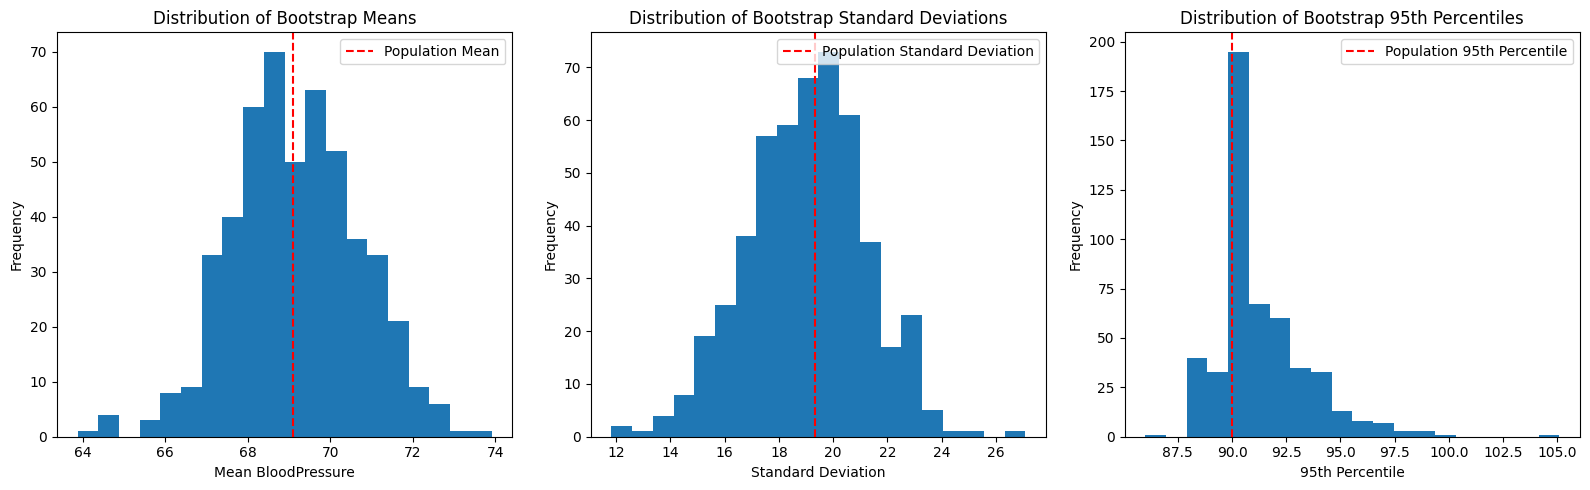

In [40]:
#Create histograms of the bootstrap statistics
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

#Distribution of bootstrap means
axes[0].hist(bootstrap_means, bins=20)
axes[0].axvline(
    population_bp_mean,
    color='red',
    linestyle='--',
    label='Population Mean'
)
axes[0].set_title('Distribution of Bootstrap Means')
axes[0].set_xlabel('Mean BloodPressure')
axes[0].set_ylabel('Frequency')
axes[0].legend()

#Distribution of bootstrap standard deviations
axes[1].hist(bootstrap_standard_deviations, bins=20)
axes[1].axvline(
    population_bp_std,
    color='red',
    linestyle='--',
    label='Population Standard Deviation'
)
axes[1].set_title(
    'Distribution of Bootstrap Standard Deviations'
)
axes[1].set_xlabel('Standard Deviation')
axes[1].set_ylabel('Frequency')
axes[1].legend()

#Distribution of bootstrap percentiles
axes[2].hist(bootstrap_percentiles, bins=20)
axes[2].axvline(
    population_bp_percentile,
    color='red',
    linestyle='--',
    label='Population 95th Percentile'
)
axes[2].set_title(
    'Distribution of Bootstrap 95th Percentiles'
)
axes[2].set_xlabel('95th Percentile')
axes[2].set_ylabel('Frequency')
axes[2].legend()

plt.tight_layout()
plt.show()

**Part C (explanation): Bootstrap Analysis of Blood Pressure**

A bootstrap analysis was performed by creating 500 samples of 150 observations each from the population using sampling with replacement. A random seed of 42 was used to ensure reproducibility. For each bootstrap sample, the mean, standard deviation, and 95th percentile of BloodPressure were calculated. Because the assignment did not specify a percentile level, the 95th percentile was used for the comparison. The results from the 500 samples were then averaged and compared with the corresponding population statistics.

The average bootstrap mean was 69.18, which was very close to the population mean of 69.11, with a difference of only 0.07. The average bootstrap standard deviation was 19.01, compared with the population standard deviation of 19.34. This made the bootstrap value 0.33 lower. The average bootstrap 95th percentile was 91.13, compared with the population 95th percentile of 90.00, making the bootstrap value 1.13 higher.

The charts show that the average bootstrap statistics were close to the corresponding population values. The bootstrap mean showed the closest agreement with the population mean, while slightly larger differences were observed for the standard deviation and 95th percentile. Overall, the results show that repeated bootstrap sampling can produce estimates that are close to the characteristics of the original population, although some variation is expected because each bootstrap sample contains only 150 observations.